# Multiclass – Iris

**Sumber dataset:** UCI / R.A. Fisher (1936), bawaan `sklearn.datasets.load_iris` (https://archive.ics.uci.edu/dataset/53)

Ukuran sepal & petal bunga iris. Tugas: menentukan spesies (setosa, versicolor, virginica).

**Klasifikasi multikelas** = data dikelompokkan ke **lebih dari dua** kategori, dan tiap data hanya masuk ke **satu** kategori.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

def ringkas(df, fitur, target, modalitas):
    """Cetak identifikasi fitur/target, jumlah data & variabel, dan jenis klasifikasi."""
    print("Jumlah data (baris)      :", df.shape[0])
    print("Jumlah variabel (kolom)  :", df.shape[1])
    print("Jumlah fitur             :", len(fitur))
    print("Jumlah kolom target      :", len(target))
    print("Modalitas data           :", modalitas)
    print("Contoh fitur             :", [str(x) for x in fitur[:6]], "..." if len(fitur) > 6 else "")
    print("Target (label)           :", [str(x) for x in target[:6]], "..." if len(target) > 6 else "")
    if len(target) == 1:
        k = df[target[0]].nunique()
        jenis = "Klasifikasi Biner" if k == 2 else "Klasifikasi Multikelas"
        print(f"Jumlah kelas             : {k}")
        print("Distribusi kelas         :\n", df[target[0]].value_counts().to_string())
    else:
        per_baris = df[target].sum(axis=1)
        print("Rata-rata label/sampel   :", round(per_baris.mean(), 2), "| maks:", per_baris.max())
        jenis = "Klasifikasi Multilabel"
    print("\n>>> KESIMPULAN:", jenis)
    return jenis

## 1. Muat dataset & ubah ke DataFrame

In [2]:
from sklearn.datasets import load_iris
data = load_iris(as_frame=True)
df = data.frame.copy()
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


## 2. Identifikasi fitur, target, jumlah data & variabel

In [3]:
fitur = list(data.feature_names)
target = ['target']
ringkas(df, fitur, target, "Tabular (numerik)")
nama_kelas = dict(enumerate(map(str, data.target_names)))
print("Makna label:", nama_kelas)

Jumlah data (baris)      : 150
Jumlah variabel (kolom)  : 5
Jumlah fitur             : 4
Jumlah kolom target      : 1
Modalitas data           : Tabular (numerik)
Contoh fitur             : ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)'] 
Target (label)           : ['target'] 
Jumlah kelas             : 3
Distribusi kelas         :
 target
0    50
1    50
2    50

>>> KESIMPULAN: Klasifikasi Multikelas
Makna label: {0: 'setosa', 1: 'versicolor', 2: 'virginica'}


## 3. Eksplorasi data

In [4]:
print("Tipe data tiap kolom:")
df.info()
print("\nNilai kosong:", int(df.isna().sum().sum()))

print("\nStatistik deskriptif:")
display(df[fitur].describe().round(2))

print("\nRata-rata tiap fitur per spesies:")
display(df.groupby(df['target'].map(nama_kelas))[fitur].mean().round(2))

Tipe data tiap kolom:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB

Nilai kosong: 0

Statistik deskriptif:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50



Rata-rata tiap fitur per spesies:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
target,,,,
setosa,5.01,3.43,1.46,0.25
versicolor,5.94,2.77,4.26,1.33
virginica,6.59,2.97,5.55,2.03


## 4. Visualisasi

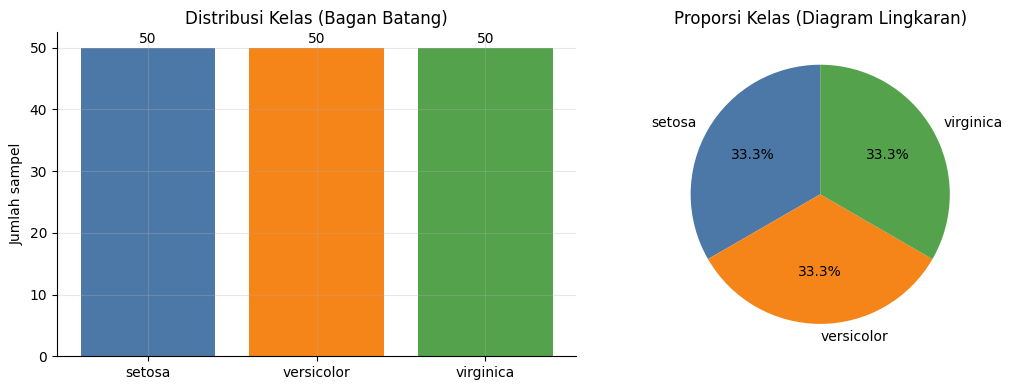

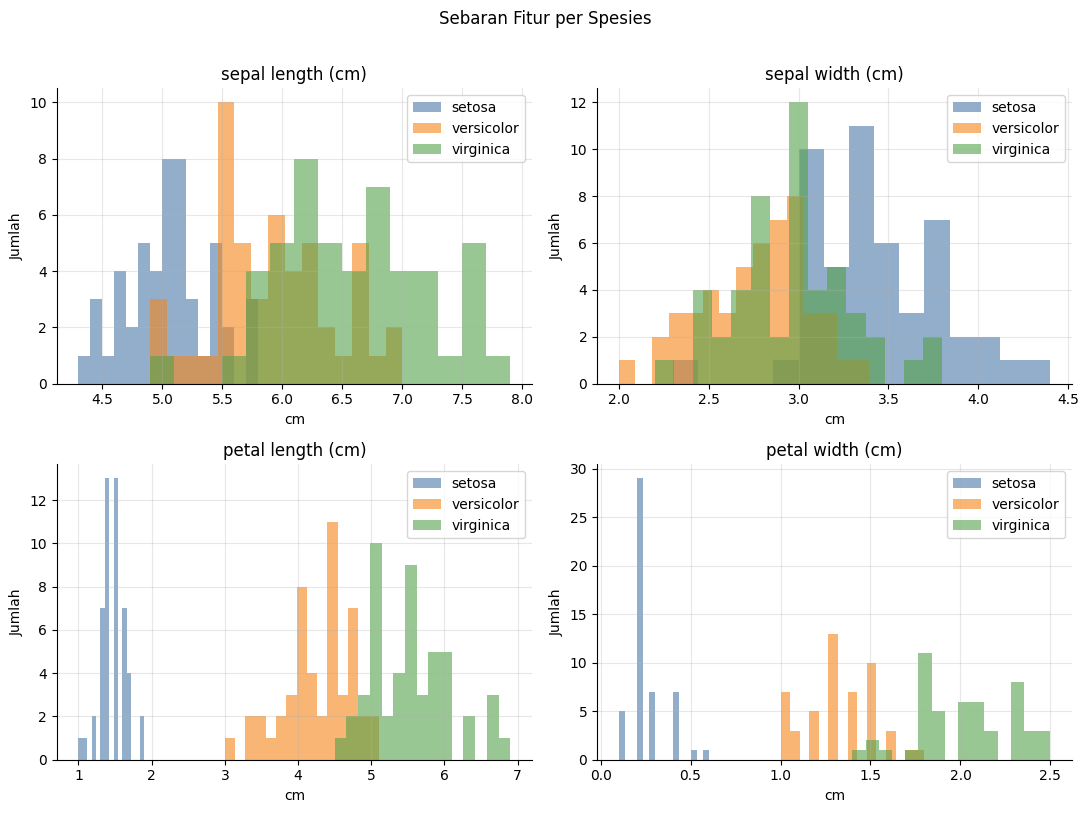

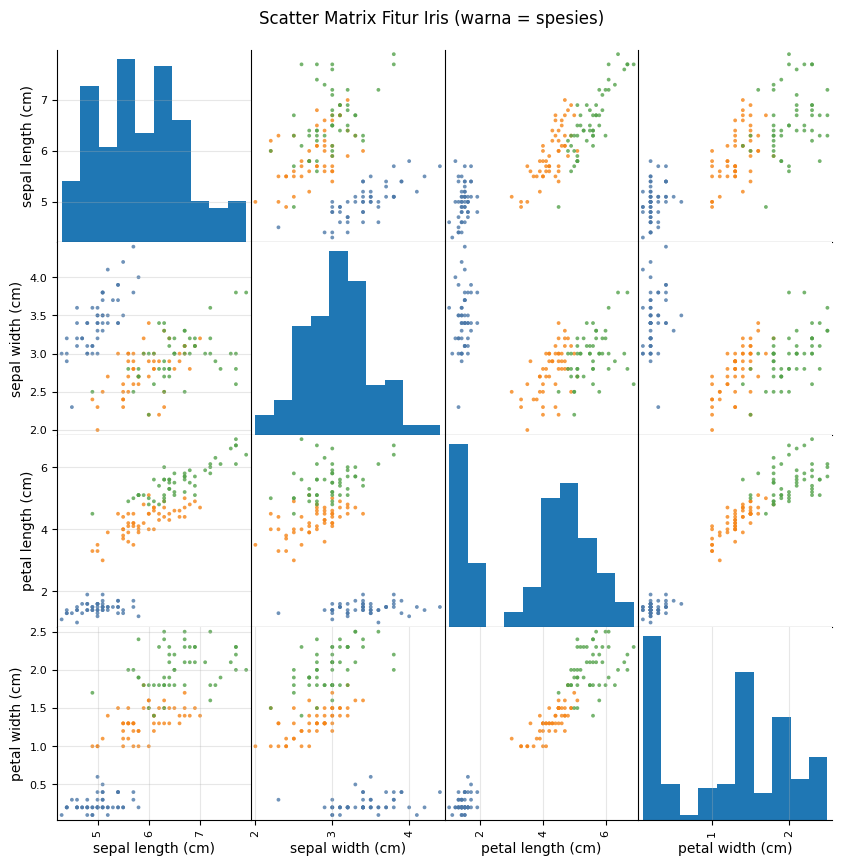

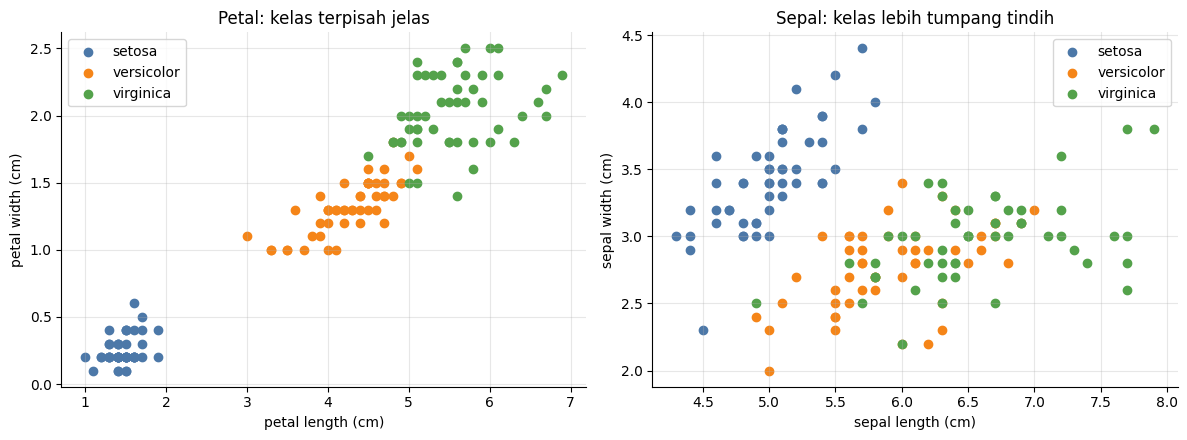

C:\Users\kholilah\AppData\Local\Temp\ipykernel_22700\1951805928.py:49: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([dv.loc[dv['spesies'] == sp, f] for sp in urutan], labels=urutan)
C:\Users\kholilah\AppData\Local\Temp\ipykernel_22700\1951805928.py:49: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([dv.loc[dv['spesies'] == sp, f] for sp in urutan], labels=urutan)
C:\Users\kholilah\AppData\Local\Temp\ipykernel_22700\1951805928.py:49: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([dv.loc[dv['spesies'] == sp, f] for sp in urutan], labels=urutan)
C:\Users\kholilah\AppData\Local\Temp\ipyker

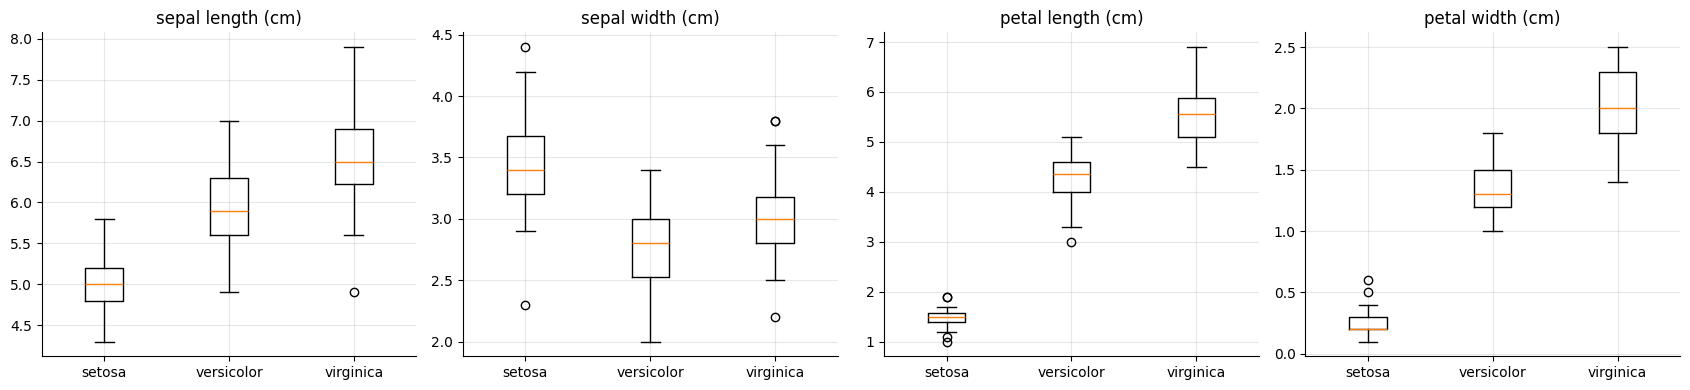

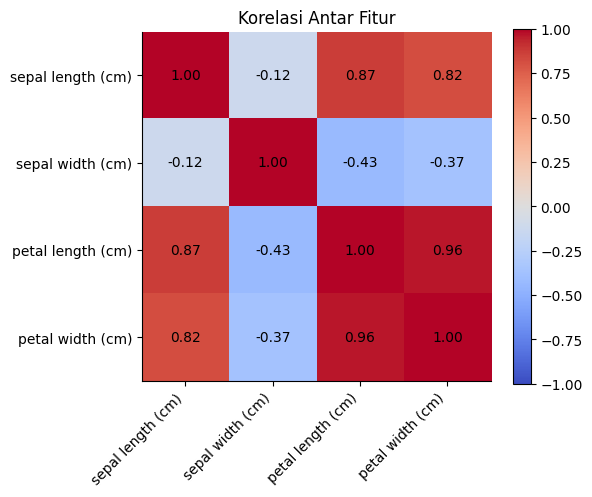

In [5]:
dv = df.copy()
dv['spesies'] = dv['target'].map(nama_kelas)
warna = {'setosa': '#4c78a8', 'versicolor': '#f58518', 'virginica': '#54a24b'}
urutan = list(warna.keys())

# --- 4a. Distribusi kelas: batang + lingkaran
cnt = dv['spesies'].value_counts().reindex(urutan)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(cnt.index, cnt.values, color=[warna[s] for s in cnt.index])
for i, v in enumerate(cnt.values):
    ax[0].text(i, v + 0.8, str(v), ha='center')
ax[0].set_title('Distribusi Kelas (Bagan Batang)'); ax[0].set_ylabel('Jumlah sampel')
ax[1].pie(cnt.values, labels=cnt.index, autopct='%1.1f%%',
          colors=[warna[s] for s in cnt.index], startangle=90)
ax[1].set_title('Proporsi Kelas (Diagram Lingkaran)')
plt.tight_layout(); plt.show()

# --- 4b. Histogram tiap fitur per spesies
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, f in zip(axes.ravel(), fitur):
    for sp in urutan:
        ax.hist(dv.loc[dv['spesies'] == sp, f], bins=15, alpha=0.6, color=warna[sp], label=sp)
    ax.set_title(f); ax.set_xlabel('cm'); ax.set_ylabel('Jumlah'); ax.legend()
plt.suptitle('Sebaran Fitur per Spesies', y=1.01)
plt.tight_layout(); plt.show()

# --- 4c. Scatter matrix (semua pasangan fitur)
from pandas.plotting import scatter_matrix
warna_titik = dv['spesies'].map(warna)
scatter_matrix(dv[fitur], c=warna_titik, figsize=(10, 10), diagonal='hist', alpha=0.8, s=30)
plt.suptitle('Scatter Matrix Fitur Iris (warna = spesies)', y=0.92)
plt.show()

# --- 4d. Scatter petal & sepal
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for sp in urutan:
    sub = dv[dv['spesies'] == sp]
    ax[0].scatter(sub['petal length (cm)'], sub['petal width (cm)'], color=warna[sp], label=sp)
    ax[1].scatter(sub['sepal length (cm)'], sub['sepal width (cm)'], color=warna[sp], label=sp)
ax[0].set_xlabel('petal length (cm)'); ax[0].set_ylabel('petal width (cm)')
ax[0].set_title('Petal: kelas terpisah jelas'); ax[0].legend()
ax[1].set_xlabel('sepal length (cm)'); ax[1].set_ylabel('sepal width (cm)')
ax[1].set_title('Sepal: kelas lebih tumpang tindih'); ax[1].legend()
plt.tight_layout(); plt.show()

# --- 4e. Boxplot fitur per spesies
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, f in zip(axes, fitur):
    ax.boxplot([dv.loc[dv['spesies'] == sp, f] for sp in urutan], labels=urutan)
    ax.set_title(f)
plt.tight_layout(); plt.show()

# --- 4f. Heatmap korelasi antar fitur
kor = df[fitur].corr()
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(kor, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(fitur))); ax.set_xticklabels(fitur, rotation=45, ha='right')
ax.set_yticks(range(len(fitur))); ax.set_yticklabels(fitur)
for i in range(len(fitur)):
    for j in range(len(fitur)):
        ax.text(j, i, f"{kor.iloc[i, j]:.2f}", ha='center', va='center')
ax.grid(False); ax.set_title('Korelasi Antar Fitur')
plt.colorbar(im); plt.tight_layout(); plt.show()

## 5. Kesimpulan

- **Fitur (X):** 4 kolom (sepal length/width, petal length/width)
- **Target (y):** `target` (0 = setosa, 1 = versicolor, 2 = virginica)
- **Jenis data:** tabular numerik
- **Jenis klasifikasi: Multikelas** — 3 kelas dengan jumlah seimbang (50:50:50), dan tiap sampel hanya masuk ke tepat satu kelas.